### **installing the libraries we will be using**

In [ ]:
!pip install ultralytics

import os
import pandas as pd
from PIL import Image
import cv2
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

### **mounting drive to retrive the data folder**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


initializing the model for this file we used YOLO version 11 small  

In [ ]:
model = YOLO('yolo11s.pt')

100%|██████████| 18.4M/18.4M [00:00<00:00, 192MB/s]


initializing a variable that holds the path for data.yaml file

In [ ]:
yamlFilePath = '/content/drive/MyDrive/BrainTumorYolov11/data.yaml'

In [ ]:
print(os.path.exists('yolo11s.pt'))

True


training the model for 50 epochs

In [ ]:
result = model.train(data = yamlFilePath, epochs = 50,patience=20, batch= 16, optimizer='auto',device = 0)

Ultralytics 8.3.137 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/BrainTumorYolov11/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train11, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=20, perspective=0.0, plots=True, p

100%|██████████| 5.35M/5.35M [00:00<00:00, 96.2MB/s]


AMP: checks passed ✅
train: Fast image access ✅ (ping: 1.0±0.1 ms, read: 14.9±11.0 MB/s, size: 31.9 KB)


train: Scanning /content/drive/MyDrive/BrainTumorYolov11/train/labels... 2144 images, 0 backgrounds, 0 corrupt: 100%|██████████| 2144/2144 [07:56<00:00,  4.50it/s]


train: New cache created: /content/drive/MyDrive/BrainTumorYolov11/train/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 2143, len(boxes) = 2144. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
val: Fast image access ✅ (ping: 0.5±0.2 ms, read: 0.1±0.0 MB/s, size: 34.0 KB)


val: Scanning /content/drive/MyDrive/BrainTumorYolov11/valid/labels... 612 images, 0 backgrounds, 0 corrupt: 100%|██████████| 612/612 [03:49<00:00,  2.66it/s]

... (145 outputs left out)

                   all        612        612      0.897      0.874      0.916      0.694



50 epochs completed in 0.748 hours.
Optimizer stripped from runs/detect/train11/weights/last.pt, 19.2MB
Optimizer stripped from runs/detect/train11/weights/best.pt, 19.2MB

Validating runs/detect/train11/weights/best.pt...
Ultralytics 8.3.137 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11s summary (fused): 100 layers, 9,413,961 parameters, 0 gradients, 21.3 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 20/20 [00:08<00:00,  2.42it/s]


                   all        612        612      0.896      0.874      0.916      0.694
                glioma        285        285      0.804      0.765      0.817      0.533
            meningioma        142        142      0.971      0.937      0.967      0.805
             pituitary        185        185      0.914       0.92      0.964      0.744
Speed: 0.2ms preprocess, 4.9ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to runs/detect/train11


In [ ]:
postTrainingFilePath = '/content/runs/detect'

In [ ]:
bestModelPath = os.path.join(postTrainingFilePath, '/content/runs/detect/train11/weights/best.pt')

In [ ]:
bestModel = YOLO(bestModelPath)

In [ ]:
metrics = bestModel.val(split='val')

Ultralytics 8.3.137 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11s summary (fused): 100 layers, 9,413,961 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.0 ms, read: 15.9±5.7 MB/s, size: 30.9 KB)


val: Scanning /content/drive/MyDrive/BrainTumorYolov11/valid/labels.cache... 612 images, 0 backgrounds, 0 corrupt: 100%|██████████| 612/612 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 39/39 [00:12<00:00,  3.03it/s]


                   all        612        612      0.898      0.873      0.916      0.695
                glioma        285        285       0.81      0.762      0.817      0.533
            meningioma        142        142      0.971      0.937      0.967      0.804
             pituitary        185        185      0.914      0.919      0.964      0.747
Speed: 1.2ms preprocess, 9.1ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to runs/detect/val


(np.float64(-0.5), np.float64(2999.5), np.float64(2249.5), np.float64(-0.5))

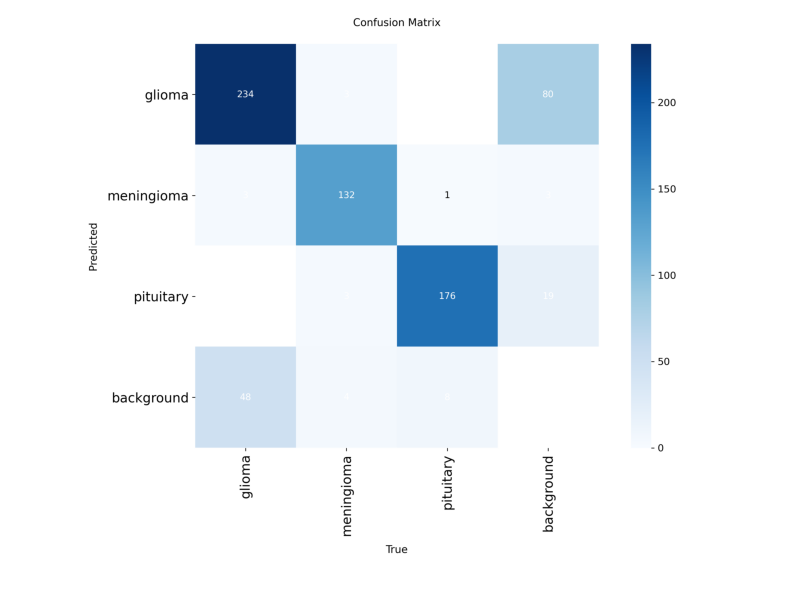

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread('/content/runs/detect/train11/confusion_matrix.png')
plt.figure(figsize=(10, 10))  # width, height in inches
plt.imshow(img)
plt.axis('off')

## Observations:
**Glioma:**
True Positives (TP): 234 — correctly predicted as glioma.

False Negatives (FN):

80 misclassified as background

3 misclassified as meningioma

3 misclassified as pituitary

**Meningioma:**
  TP: 132

FN:

1 to glioma

1 to pituitary

2 to background
**Pituitary:**
 TP: 176

FN:

3 to glioma

19 to background

2 to meningioma









(np.float64(-0.5), np.float64(1919.5), np.float64(1919.5), np.float64(-0.5))

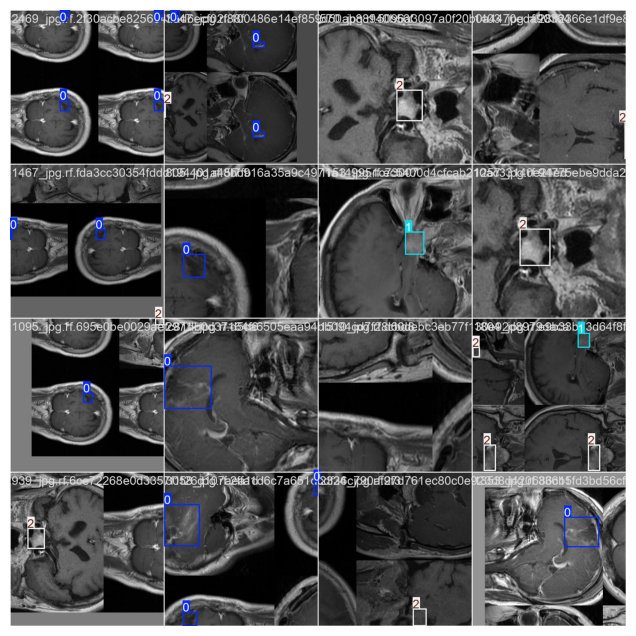

In [ ]:
img = mpimg.imread('/content/runs/detect/train11/train_batch0.jpg')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

2 for pituitary
1 for meningioma
0 for glioma

(np.float64(-0.5), np.float64(1919.5), np.float64(1919.5), np.float64(-0.5))

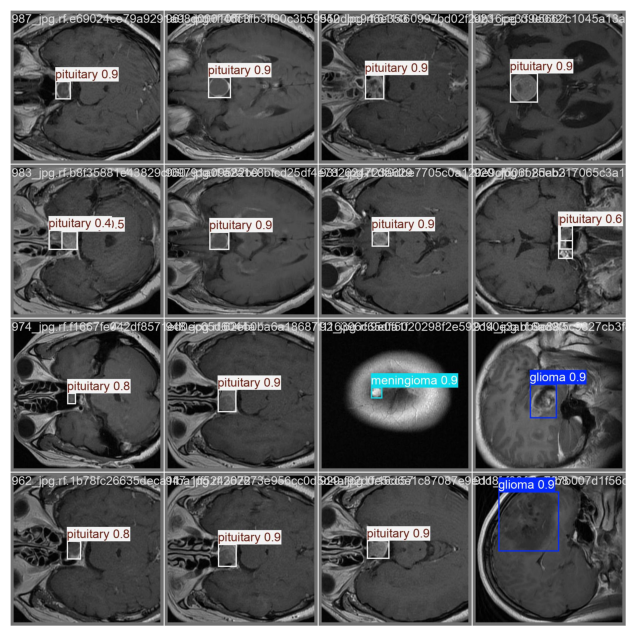

In [ ]:
img = mpimg.imread('/content/runs/detect/train11/val_batch0_pred.jpg')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

(np.float64(-0.5), np.float64(1919.5), np.float64(1919.5), np.float64(-0.5))

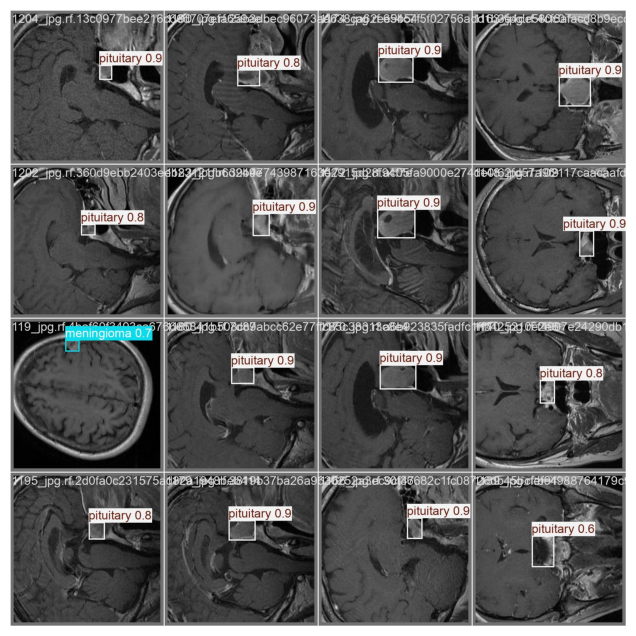

In [ ]:
img = mpimg.imread('/content/runs/detect/train11/val_batch1_pred.jpg')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

(np.float64(-0.5), np.float64(1919.5), np.float64(1919.5), np.float64(-0.5))

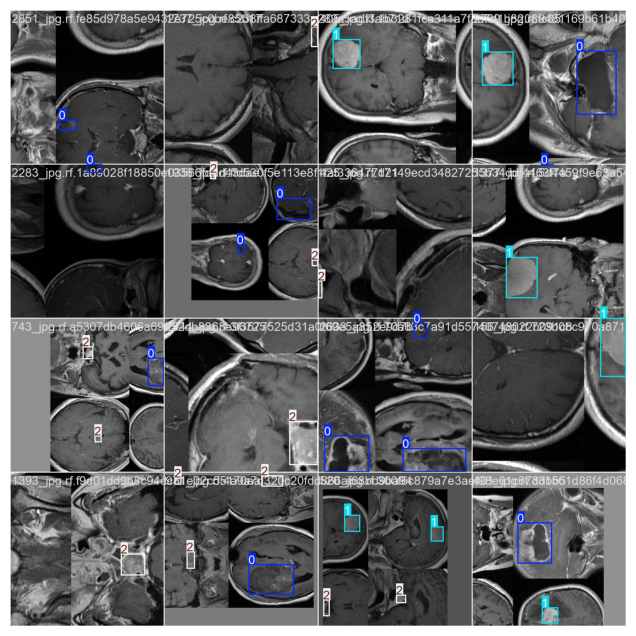

In [ ]:
img = mpimg.imread('/content/runs/detect/train/train_batch2.jpg')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

(np.float64(-0.5), np.float64(1919.5), np.float64(1919.5), np.float64(-0.5))

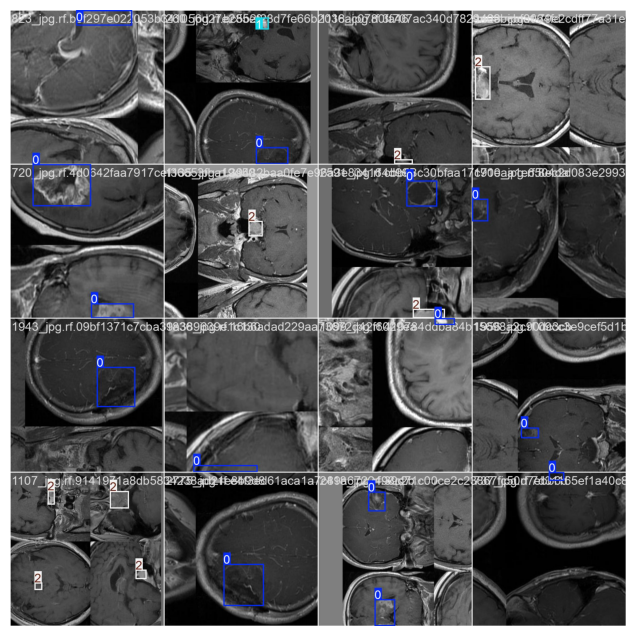

In [ ]:
img = mpimg.imread('/content/runs/detect/train11/train_batch2.jpg')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

(np.float64(-0.5), np.float64(1919.5), np.float64(1919.5), np.float64(-0.5))

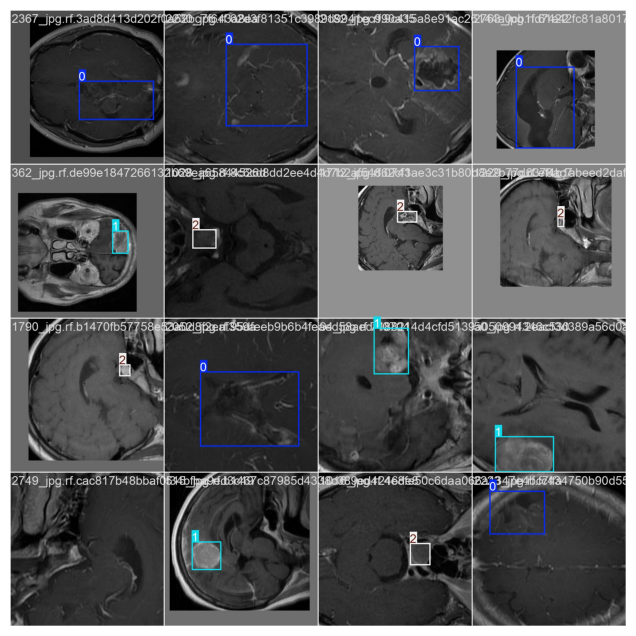

In [ ]:
img = mpimg.imread('/content/runs/detect/train11/train_batch5362.jpg')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

(np.float64(-0.5), np.float64(1919.5), np.float64(1919.5), np.float64(-0.5))

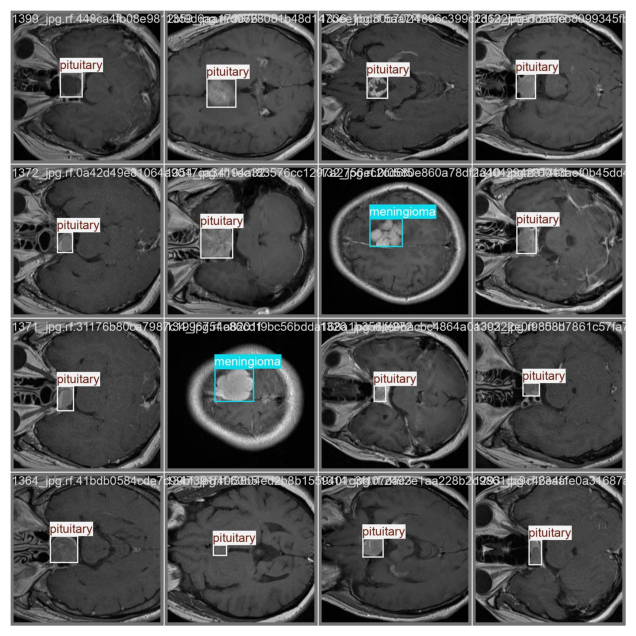

In [ ]:
img = mpimg.imread('/content/runs/detect/train11/val_batch2_labels.jpg')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

(np.float64(-0.5), np.float64(1919.5), np.float64(1919.5), np.float64(-0.5))

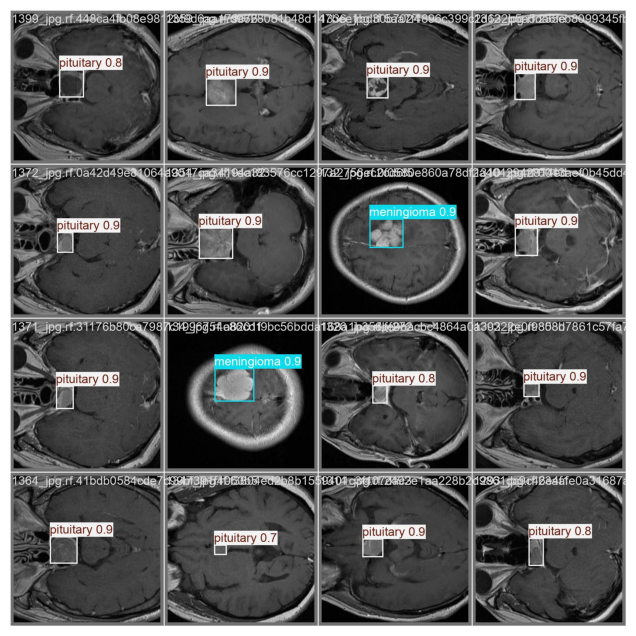

In [ ]:
img = mpimg.imread('/content/runs/detect/train11/val_batch2_pred.jpg')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

(np.float64(-0.5), np.float64(2249.5), np.float64(1499.5), np.float64(-0.5))

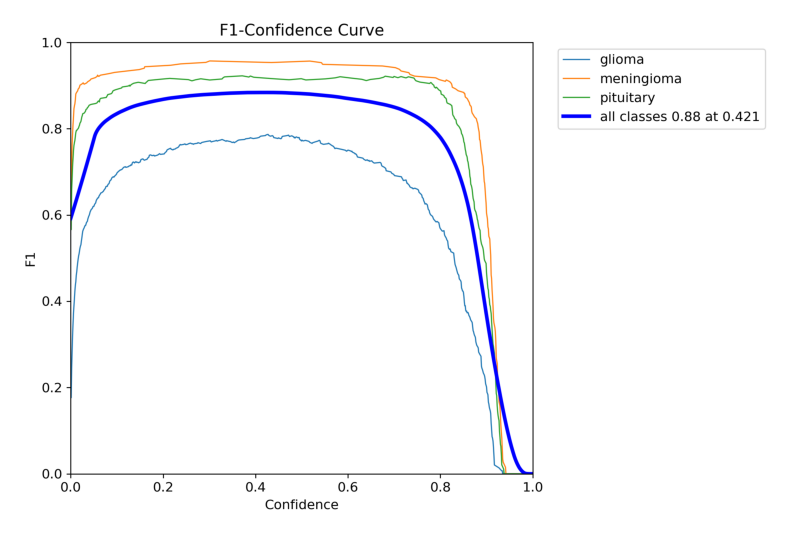

In [ ]:
img = mpimg.imread('/content/runs/detect/train11/F1_curve.png')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

## F1-Confidence Curve

| Class      | F1 Quality             | Stability Across Confidence | Comments                        |
| ---------- | ---------------------- | --------------------------- | ------------------------------- |
| Glioma     | Moderate (\~0.74 peak) | Unstable, drops sharply     | Harder to detect with certainty |
| Meningioma | Excellent (\~0.93)     | Very stable                 | Well learned                    |
| Pituitary  | Excellent (\~0.91)     | Very stable                 | Well learned                    |
| All        | 0.88 at 0.421          | Balanced                    | Model performs well overall     |


(np.float64(-0.5), np.float64(2249.5), np.float64(1499.5), np.float64(-0.5))

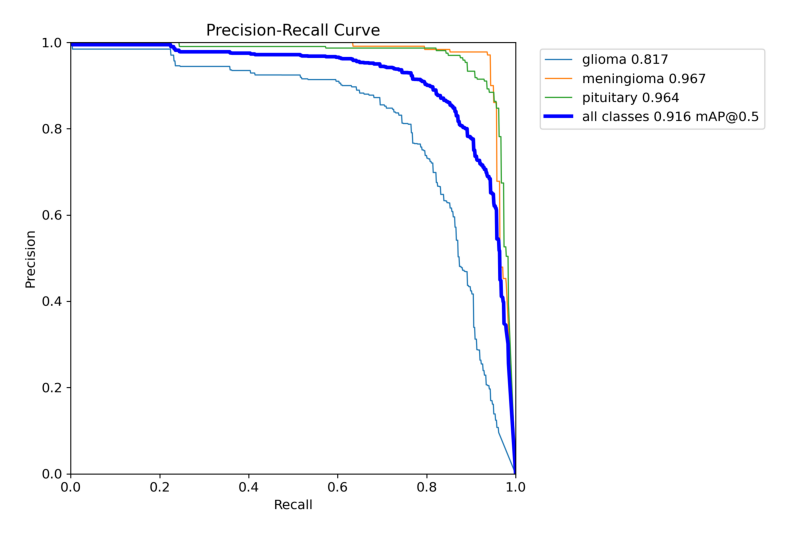

In [ ]:
img = mpimg.imread('/content/runs/detect/train11/PR_curve.png')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

## Precision-Recall Curve

| Class           | AP (mAP\@0.5) | PR Curve Behavior   | Detection Quality            |
| --------------- | ------------- | ------------------- | ---------------------------- |
| **Glioma**      | 0.817         | Lower, drops faster | Moderate – needs improvement |
| **Meningioma**  | 0.967         | High & stable       | Excellent                    |
| **Pituitary**   | 0.964         | High & stable       | Excellent                    |
| **All Classes** | 0.916         | Balanced overall    | Very strong overall model    |



(np.float64(-0.5), np.float64(2249.5), np.float64(1499.5), np.float64(-0.5))

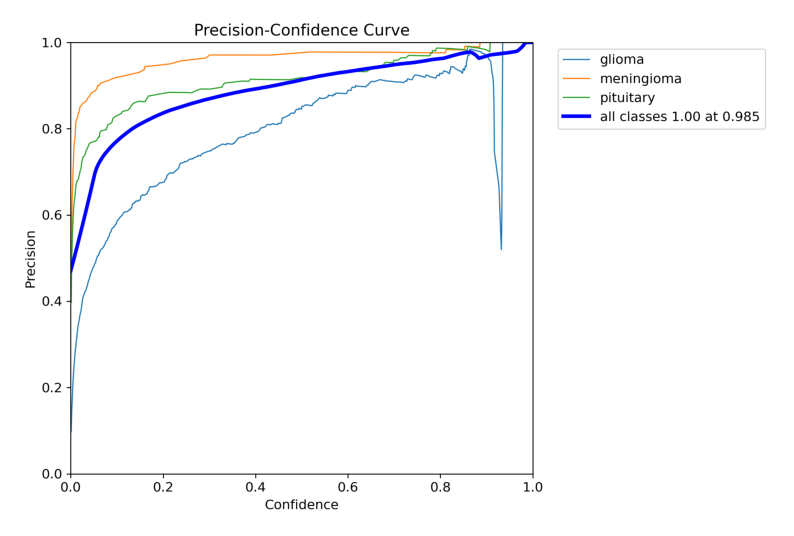

In [ ]:
img = mpimg.imread('/content/runs/detect/train11/P_curve.png')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

## Precision-Confidence Curve

| Class           | Precision Trend                    | Stability | Comments                               |
| --------------- | ---------------------------------- | --------- | -------------------------------------- |
| **Glioma**      | Low to moderate, unstable near 1.0 | ❌ Low     | Difficult to predict confidently       |
| **Meningioma**  | High and stable                    | ✅ High    | Very strong precision                  |
| **Pituitary**   | High and stable                    | ✅ High    | Very strong precision                  |
| **All Classes** | Peaks at 1.00 @ 0.985 conf         | ✅ High    | But possibly filters out hard examples |





(np.float64(-0.5), np.float64(2249.5), np.float64(1499.5), np.float64(-0.5))

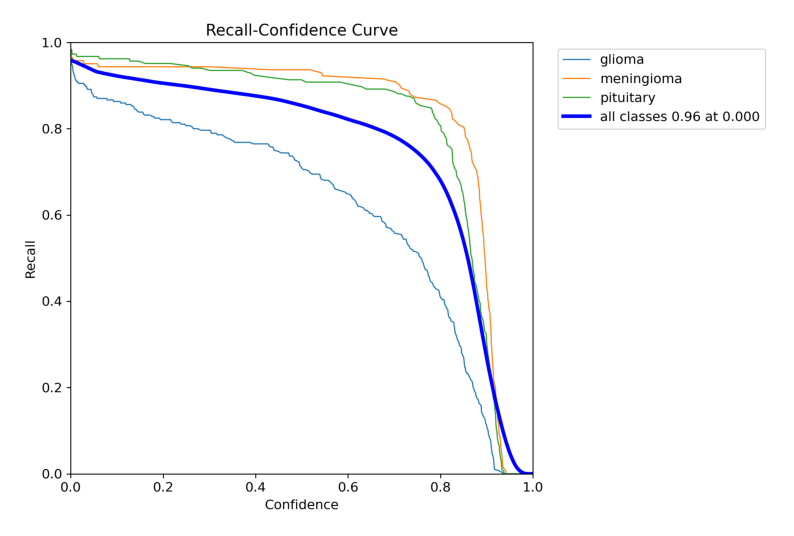

In [ ]:
img = mpimg.imread('/content/runs/detect/train11/R_curve.png')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

## Recall-Confidence Curve

| Class           | Recall Stability | High Confidence Impact      | Comments                             |
| --------------- | ---------------- | --------------------------- | ------------------------------------ |
| **Glioma**      | Poor             | High thresholds hurt recall | Many predictions have low confidence |
| **Meningioma**  | Excellent        | Stable across thresholds    | Model is confident                   |
| **Pituitary**   | Excellent        | Stable across thresholds    | Model is confident                   |
| **All Classes** | Good             | Moderate decline            | Driven mainly by glioma behavior     |


# verdict on the model

**Strengths of the Model**


High overall performance:

mAP@0.5 = 0.916, indicating excellent localization and detection across all classes.

F1 score peak = 0.88, showing good balance of precision and recall.

Meningioma and pituitary detection is excellent:

Stable, high precision and recall across all confidence thresholds.

Well-separated in feature space — the model is confident and consistent in detecting these tumors.

No signs of overfitting: Curves are smooth, and performance is consistent across metrics.


**Weaknesses – Glioma Class**

Glioma detection is the bottleneck:

Lower AP (0.817) compared to other classes (0.96+).

Recall drops rapidly with increasing confidence → model lacks confidence in glioma predictions.

High rate of misclassification as background (80 FN) in confusion matrix.

Glioma F1 peaks lower and degrades faster than other classes.

Confidence calibration is poor for glioma:

Many true glioma detections are assigned low confidence scores, which are filtered out at higher thresholds.

Affects both precision-confidence and recall-confidence behavior.




(np.float64(-0.5), np.float64(1599.5), np.float64(1599.5), np.float64(-0.5))

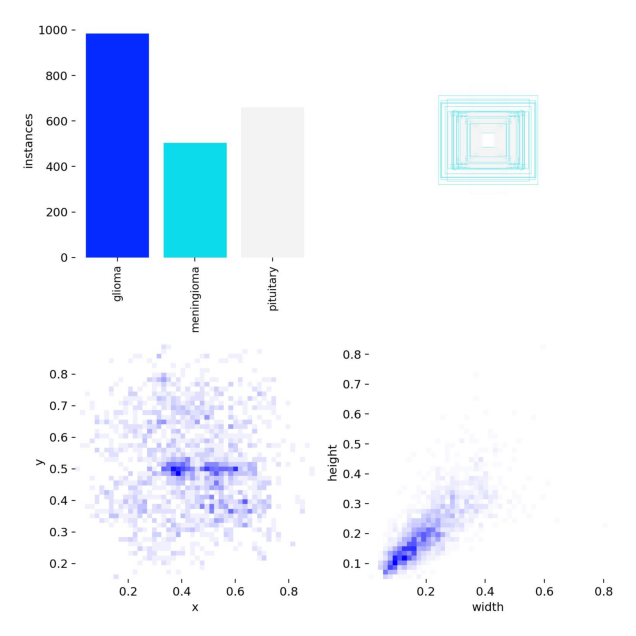

In [ ]:
img = mpimg.imread('/content/runs/detect/train11/labels.jpg')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

(np.float64(-0.5), np.float64(2399.5), np.float64(1199.5), np.float64(-0.5))

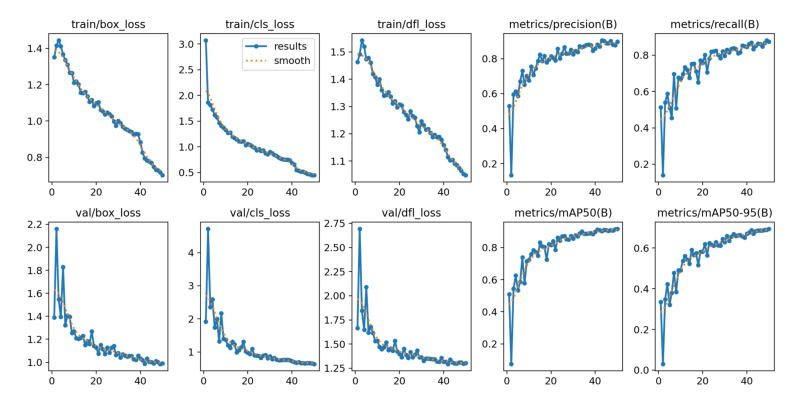

In [ ]:
img = mpimg.imread('/content/runs/detect/train11/results.png')
plt.figure(figsize=(10, 8))  # width, height in inches
plt.imshow(img)
plt.axis('off')

| Loss Type                         | Behavior                 | Interpretation                                                      |
| --------------------------------- | ------------------------ | ------------------------------------------------------------------- |
| **Box Loss**                      | Smooth, steady decline   | The model is consistently improving in localizing bounding boxes. ✅ |
| **Classification Loss (cls)**     | Decreasing cleanly       | The model is learning to classify objects well. ✅                   |
| **Distribution Focal Loss (dfl)** | Also decreasing steadily | Indicates better bounding box quality/refinement. ✅                 |


validation Losses show the same trend, and importantly, they track closely with training losses.

This strongly suggests the model is not overfitting and is generalizing well to unseen data.



| Metric            | Trend                     | Interpretation                                        |
| ----------------- | ------------------------- | ----------------------------------------------------- |
| **Precision**     | Increasing to \~0.90      | The model increasingly makes fewer false positives. ✅ |
| **Recall**        | Increasing to \~0.88      | The model is detecting more true positives. ✅         |
| **mAP\@0.5**      | Rises to \~0.916          | Very good detection quality at standard threshold. ✅  |
| **mAP\@0.5–0.95** | Climbs steadily to \~0.67 | Strong performance across stricter IoU thresholds. ✅  |

 No signs of plateauing too early or noisy learning → the training is stable, effective, and well-optimized.


 **final summary**


 the model Was trained correctly and efficiently.

Converged well, with no signs of overfitting.

Achieved high performance across standard detection metrics.

Has room to improve specifically for glioma, but this is a data/class-specific issue, not a training flaw.